# LesioScan — Single Image Prediction + Grad-CAM

**Purpose:** Test the trained **ShuffleNet V2 x1.0** directly from your Google Drive checkpoint. Upload an image, inspect six class scores, and visualize model attention via **Grad-CAM**.

**Research demo only:** These outputs cannot diagnose skin disease. Grad-CAM visualizes model sensitivity, not medical evidence or a verified lesion boundary. No retraining or test-set evaluation occurs here.

## 1. Setup — Drive, GitHub, and device

In [12]:
from pathlib import Path
import sys

REPO = Path("/content/lesioscan-ml")
SRC = REPO / "src"

print("Repository tersedia:", REPO.exists())
print("Folder src tersedia:", SRC.exists())

print("training.py tersedia:",
      (SRC / "lesioscan/training.py").is_file())

print("preprocessing.py tersedia:",
      (SRC / "lesioscan/preprocessing.py").is_file())

if SRC.exists():
    print("\nIsi folder src:")
    for path in SRC.rglob("*.py"):
        print("-", path.relative_to(SRC))

Repository tersedia: True
Folder src tersedia: True
training.py tersedia: True
preprocessing.py tersedia: True

Isi folder src:
- lesioscan/data_paths.py
- lesioscan/eda_pipeline.py
- lesioscan/data.py
- lesioscan/metrics.py
- lesioscan/preprocessing.py
- lesioscan/splitting.py
- lesioscan/config.py
- lesioscan/feature_extraction.py
- lesioscan/__init__.py
- lesioscan/training.py
- lesioscan/fine_tuning.py
- lesioscan/cleaning.py
- lesioscan/dataset.py
- lesioscan/engine.py
- lesioscan/evaluation.py
- lesioscan/inference.py
- lesioscan/models.py
- lesioscan/preprocessing_pipeline.py


In [14]:
import sys
import importlib
import inspect
from pathlib import Path

REPO = Path("/content/lesioscan-ml")
SRC = REPO / "src"

# Tambahkan src ke Python import path
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

# Perbarui cache import
importlib.invalidate_caches()

# Import modul training
import lesioscan.training as training

print("✅ Modul training berhasil diimpor")
print("Lokasi:", training.__file__)

# Periksa fungsi make_model
print("\nmake_model tersedia:", hasattr(training, "make_model"))

if hasattr(training, "make_model"):
    print("Signature:", inspect.signature(training.make_model))
else:
    print("\nFungsi yang tersedia:")
    for name in dir(training):
        if not name.startswith("_"):
            print("-", name)

✅ Modul training berhasil diimpor
Lokasi: /content/lesioscan-ml/src/lesioscan/training.py

make_model tersedia: True
Signature: (pretrained=True)


## 2. Load best checkpoint — no retraining

In [16]:
import torch
from pathlib import Path

from lesioscan.training import make_model
from lesioscan.preprocessing import build_transforms, CLASSES

# Lokasi checkpoint di Google Drive
ROOT = Path("/content/drive/MyDrive/LesioScan-AI")

MODEL_DIR = (
    ROOT
    / "experiments/training/shufflenet_v2_baseline/fine_tuning"
)

MODEL_PATH = MODEL_DIR / "best_finetuning_eval.pt"

if not MODEL_PATH.is_file():
    raise FileNotFoundError(
        f"Checkpoint belum ditemukan: {MODEL_PATH}"
    )

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Membaca checkpoint evaluasi
checkpoint = torch.load(
    MODEL_PATH,
    map_location="cpu",
    weights_only=True
)

assert checkpoint["classes"] == list(CLASSES), (
    "Urutan kelas checkpoint tidak cocok."
)

# Membuat arsitektur ShuffleNet V2
model = make_model(pretrained=False)

# Memasukkan bobot hasil Fine-Tuning
model.load_state_dict(
    checkpoint["model_state_dict"]
)

model = model.to(DEVICE)
model.eval()

# Preprocessing yang sama seperti saat validation
_, eval_transform = build_transforms(
    checkpoint["image_size"]
)

print("✅ Model LesioScan berhasil dimuat!")
print("Device:", DEVICE)
print("Best Epoch:", checkpoint["epoch"])
print("Classes:", list(CLASSES))

✅ Model LesioScan berhasil dimuat!
Device: cpu
Best Epoch: 15
Classes: ['ACK', 'BCC', 'MEL', 'NEV', 'SCC', 'SEK']


## 3. Upload one JPG/PNG image

Saving nevuslagi.jpg to nevuslagi.jpg
✅ Gambar berhasil dimuat
Filename: nevuslagi.jpg
Resolution: (673, 422)


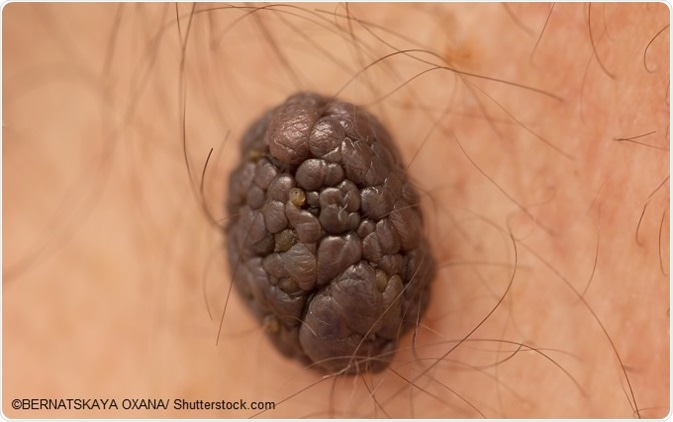

In [39]:
from google.colab import files
from PIL import Image
from IPython.display import display

uploaded = files.upload()

if not uploaded:
    raise ValueError("Belum ada gambar yang diunggah.")

filename = next(iter(uploaded))

image = Image.open(filename).convert("RGB")

print("✅ Gambar berhasil dimuat")
print("Filename:", filename)
print("Resolution:", image.size)

display(image)

## 4. Predictions — all six classes

In [40]:
import torch
import pandas as pd
from IPython.display import display

# Preprocessing
input_tensor = (
    eval_transform(image)
    .unsqueeze(0)
    .to(DEVICE)
)

# Inference
model.eval()

with torch.inference_mode():
    logits = model(input_tensor)

    probabilities = torch.softmax(
        logits,
        dim=1
    )[0]

scores = probabilities.cpu().numpy()

predicted_index = int(scores.argmax())
predicted_class = CLASSES[predicted_index]

# Tabel hasil prediksi
prediction_df = pd.DataFrame({
    "Class": list(CLASSES),
    "Score (%)": scores * 100
}).sort_values(
    "Score (%)",
    ascending=False
)

print("=" * 55)
print("LESIOSCAN — PREDICTION RESULTS")
print("=" * 55)

print("Predicted Class:", predicted_class)
print(f"Model Score: {scores[predicted_index] * 100:.2f}%")

display(prediction_df.round(2))

LESIOSCAN — PREDICTION RESULTS
Predicted Class: SEK
Model Score: 71.44%


,Class,Score (%)
5,SEK,71.440002
3,NEV,27.059999
2,MEL,0.660000
0,ACK,0.440000
4,SCC,0.240000
1,BCC,0.160000


## 5. Grad-CAM — attention heatmap

Grad-CAM uses gradients with respect to the final convolutional feature maps of ShuffleNet V2 (`model.conv5`). It highlights image regions contributing to the **selected class score**; it does **not** segment a lesion or verify a diagnosis. The overlay uses the same deterministic evaluation transformation as the model input.

In [44]:
import torch
import numpy as np
import torch.nn.functional as F

# Gunakan stage3 untuk feature map lebih besar
target_layer = model.stage3

activations = []
gradients = []

def forward_hook(module, inputs, output):
    activations.append(output.detach())

def backward_hook(module, grad_input, grad_output):
    gradients.append(grad_output[0].detach())

h1 = target_layer.register_forward_hook(forward_hook)
h2 = target_layer.register_full_backward_hook(backward_hook)

try:
    model.eval()
    model.zero_grad(set_to_none=True)

    with torch.enable_grad():
        output = model(input_tensor.detach())

        target_class = int(
            output.argmax(dim=1).item()
        )

        output[0, target_class].backward()

    A = activations[-1]
    G = gradients[-1]

    weights = G.mean(dim=(2, 3), keepdim=True)

    cam_tensor = torch.relu(
        (weights * A).sum(dim=1, keepdim=True)
    )

    # Upsampling langsung ke ukuran input model
    cam_tensor = F.interpolate(
        cam_tensor,
        size=input_tensor.shape[-2:],
        mode="bilinear",
        align_corners=False
    )

    cam = cam_tensor[0, 0].cpu().numpy()

    cam -= cam.min()
    cam /= cam.max() + 1e-8

finally:
    h1.remove()
    h2.remove()

print("✅ Grad-CAM berhasil dibuat")
print("Feature map:", tuple(A.shape))
print("Target class:", CLASSES[target_class])

✅ Grad-CAM berhasil dibuat
Feature map: (1, 232, 14, 14)
Target class: SEK


## 6. Optional — plot class scores and save visualizations

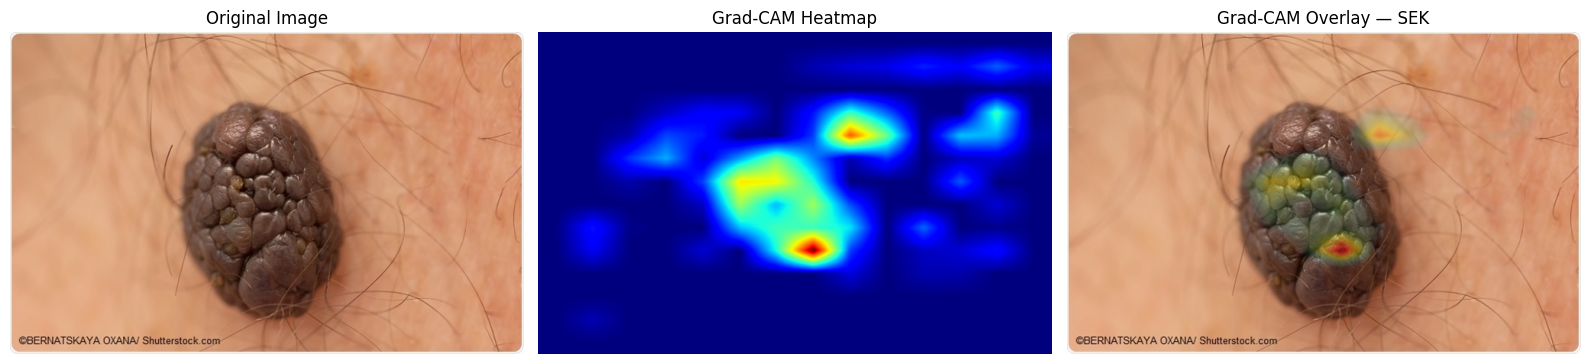

In [45]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# ==========================================
# ORIGINAL IMAGE
# ==========================================

original = np.asarray(
    image.convert("RGB"),
    dtype=np.float32
) / 255.0

height, width = original.shape[:2]

# Resize heatmap ke resolusi gambar asli
cam_resized = np.asarray(
    Image.fromarray(
        np.uint8(cam * 255)
    ).resize(
        (width, height),
        Image.Resampling.BILINEAR
    ),
    dtype=np.float32
) / 255.0

# ==========================================
# HEATMAP
# ==========================================

heatmap = plt.get_cmap("jet")(
    cam_resized
)[..., :3]

# Aktivasi rendah dibuat transparan
threshold = 0.25

alpha = np.clip(
    (cam_resized - threshold) / (1 - threshold),
    0,
    1
) * 0.6

# Tambahkan dimensi channel
alpha = alpha[..., None]

overlay = (
    (1 - alpha) * original
    + alpha * heatmap
)

overlay = np.clip(overlay, 0, 1)

# ==========================================
# VISUALIZATION
# ==========================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 5)
)

axes[0].imshow(original)
axes[0].set_title("Original Image")

axes[1].imshow(cam_resized, cmap="jet", vmin=0, vmax=1)
axes[1].set_title("Grad-CAM Heatmap")

axes[2].imshow(overlay)
axes[2].set_title(
    f"Grad-CAM Overlay — {CLASSES[target_class]}"
)

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [43]:
import numpy as np
import pandas as pd

from IPython.display import display, HTML

# ==========================================
# LESIOSCAN — PREDICTION SUMMARY
# ==========================================

CLASS_NAMES = {
    "ACK": "Actinic Keratosis",
    "BCC": "Basal Cell Carcinoma",
    "MEL": "Melanoma",
    "NEV": "Melanocytic Nevus",
    "SCC": "Squamous Cell Carcinoma",
    "SEK": "Seborrheic Keratosis"
}

# Menggunakan hasil probabilitas dari Cell 3
scores_array = np.asarray(scores, dtype=float)

assert len(scores_array) == len(CLASSES), (
    "Jumlah skor tidak sesuai dengan jumlah kelas."
)

# ==========================================
# 1. CLASS PERCENTAGES
# ==========================================

summary_df = pd.DataFrame({
    "Label": list(CLASSES),
    "Class Name": [
        CLASS_NAMES[label] for label in CLASSES
    ],
    "Model Score (%)": scores_array * 100
})

summary_df = summary_df.sort_values(
    by="Model Score (%)",
    ascending=False
).reset_index(drop=True)

summary_df.insert(
    0,
    "Rank",
    range(1, len(summary_df) + 1)
)

# ==========================================
# 2. TOP PREDICTIONS
# ==========================================

top_label = summary_df.iloc[0]["Label"]
top_name = summary_df.iloc[0]["Class Name"]
top_score = summary_df.iloc[0]["Model Score (%)"]

second_label = summary_df.iloc[1]["Label"]
second_score = summary_df.iloc[1]["Model Score (%)"]

score_margin = top_score - second_score

# ==========================================
# 3. DISPLAY REPORT
# ==========================================

print("=" * 60)
print("LESIOSCAN — PREDICTION SUMMARY")
print("=" * 60)

display(
    summary_df.style.format({
        "Model Score (%)": "{:.2f}%"
    }).background_gradient(
        subset=["Model Score (%)"],
        cmap="Blues"
    )
)

print("\n" + "=" * 60)
print("MODEL PREDICTION")
print("=" * 60)

print(f"Top Prediction : {top_label}")
print(f"Class Name     : {top_name}")
print(f"Model Score    : {top_score:.2f}%")

print(f"\nSecond Choice  : {second_label}")
print(f"Second Score   : {second_score:.2f}%")

print(f"\nScore Margin   : {score_margin:.2f} percentage points")

# ==========================================
# 4. CONCLUSION
# ==========================================

print("\n" + "=" * 60)
print("CONCLUSION")
print("=" * 60)

print(
    f"LesioScan menghasilkan skor tertinggi untuk "
    f"{top_name} ({top_label}), yaitu {top_score:.2f}%."
)

print(
    f"Skor tertinggi kedua adalah {second_label} "
    f"sebesar {second_score:.2f}%."
)

print(
    f"Selisih skor kedua kelas tersebut adalah "
    f"{score_margin:.2f} poin persentase."
)

print(
    "\nHasil ini merupakan klasifikasi berdasarkan pola "
    "visual yang dipelajari model ShuffleNet V2."
)

print(
    "Persentase yang ditampilkan merupakan skor softmax "
    "model, bukan probabilitas medis yang telah dikalibrasi."
)

print(
    "\n⚠️ LesioScan adalah prototipe penelitian, "
    "bukan alat diagnosis medis."
)

LESIOSCAN — PREDICTION SUMMARY


,Rank,Label,Class Name,Model Score (%)
0,1,SEK,Seborrheic Keratosis,71.44%
1,2,NEV,Melanocytic Nevus,27.06%
2,3,MEL,Melanoma,0.66%
3,4,ACK,Actinic Keratosis,0.44%
4,5,SCC,Squamous Cell Carcinoma,0.24%
5,6,BCC,Basal Cell Carcinoma,0.16%



MODEL PREDICTION
Top Prediction : SEK
Class Name     : Seborrheic Keratosis
Model Score    : 71.44%

Second Choice  : NEV
Second Score   : 27.06%

Score Margin   : 44.37 percentage points

CONCLUSION
LesioScan menghasilkan skor tertinggi untuk Seborrheic Keratosis (SEK), yaitu 71.44%.
Skor tertinggi kedua adalah NEV sebesar 27.06%.
Selisih skor kedua kelas tersebut adalah 44.37 poin persentase.

Hasil ini merupakan klasifikasi berdasarkan pola visual yang dipelajari model ShuffleNet V2.
Persentase yang ditampilkan merupakan skor softmax model, bukan probabilitas medis yang telah dikalibrasi.

⚠️ LesioScan adalah prototipe penelitian, bukan alat diagnosis medis.


## Interpretation and limitations

- **Predicted class:** the class with the highest model score, **not a diagnosis**.
- **Heatmap:** relative influence of regions on one class score; it may highlight hair, edges, background, or artifacts rather than the lesion.
- **Unseen photos:** may differ substantially from PAD-UFES-20. Never interpret model output as a medical recommendation.
- **Reproducibility:** the checkpoint, class order, and `build_transforms()` must match training. To test another image, rerun sections 3–6.